In [1]:
import subprocess
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import utils
from utils import SearchResult, bfs, dfs, ucs, gbfs, astar, haversine_km, load_openflights

ROOT = Path.cwd().parent
DATA = ROOT / "all_datasets"
RESULTS = ROOT / "results" / "lab03"
RESULTS.mkdir(parents=True, exist_ok=True)

In [3]:
print("SearchResult fields:", list(SearchResult.__dataclass_fields__))
toy = {"S": [("A", 2.0), ("B", 5.0)], "A": [("G", 5.0)], "B": [("G", 1.0)], "G": []}
h = {"S": 5.0, "A": 4.0, "B": 1.0, "G": 0.0}.get  # a hand-made consistent heuristic

results = {
    "BFS": bfs(toy, "S", "G"),
    "DFS": dfs(toy, "S", "G"),
    "UCS": ucs(toy, "S", "G"),
    "GBFS": gbfs(toy, "S", "G", h),
    "A*": astar(toy, "S", "G", h),
}
table = pd.DataFrame({name: r.as_dict() for name, r in results.items()}).T.drop(columns="runtime_ms")
table["path"] = table.path.map(" -> ".join)
display(table)

SearchResult fields: ['found', 'path', 'hops', 'path_cost_km', 'expanded', 'max_frontier', 'runtime_ms']


,found,path,hops,path_cost_km,expanded,max_frontier
BFS,True,S -> A -> G,2,7.0,3,2
DFS,True,S -> A -> G,2,7.0,2,2
UCS,True,S -> B -> G,2,6.0,3,2
GBFS,True,S -> B -> G,2,6.0,2,2
A*,True,S -> B -> G,2,6.0,3,2


In [5]:
package = Path(utils.__file__).parent
for module in sorted(package.glob("*.py")):
    purpose = module.read_text(encoding="utf-8").splitlines()[0].strip('"')
    print(f"{module.name:<16} {purpose}")
print("\nExported names:", ", ".join(utils.__all__))

__init__.py      Helper code for the AI course notebooks.
__main__.py      Command-line route search (Lab 3).
core.py          Graph-search algorithms shared by Labs 1-3: BFS, DFS, UCS, GBFS and A*.
openflights.py   Load the OpenFlights airport and route files into a weighted graph.
plotting.py      Plot airport routes on longitude/latitude axes (Labs 1-3).
test_search.py   Unit tests for utils.core on tiny hand-made graphs (no dataset needed).

Exported names: SearchResult, astar, best_first, bfs, dfs, gbfs, ucs, haversine_km, load_openflights, route_is_valid, plot_route_paths


In [7]:
tests = subprocess.run([sys.executable, "-m", "pytest", "utils", "-q", "--color=no"], capture_output=True, text=True)
print(tests.stdout)
assert tests.returncode == 0, tests.stderr

........                                                                 [100%]
8 passed in 1.47s



In [9]:
cli = subprocess.run([sys.executable, "-m", "utils", "--algorithm", "astar", "--start", "KUL", "--goal", "KEF"],
                     capture_output=True, text=True)
print(cli.stdout)
assert cli.returncode == 0, cli.stderr

ASTAR: found=True, hops=4, cost_km=11461.3, expanded=69, runtime_ms=5.48
KUL -> HKT -> LED -> HEL -> KEF



In [11]:
_, _, coords, graph, _ = load_openflights(DATA / "lab01-03_airports.csv", DATA / "lab01-03_routes.csv")
queries = pd.read_csv("utils/search_queries.csv")

def heuristic_to(goal):
    return lambda a: haversine_km(coords[a]["latitude"], coords[a]["longitude"],
                                  coords[goal]["latitude"], coords[goal]["longitude"])

rows = []
for query in queries.itertuples():
    h = heuristic_to(query.goal)
    results = {"BFS": bfs(graph, query.start, query.goal), "UCS": ucs(graph, query.start, query.goal),
               "GBFS": gbfs(graph, query.start, query.goal, h), "A*": astar(graph, query.start, query.goal, h)}
    for name, result in results.items():
        rows.append({"query_id": query.query_id, "start": query.start, "goal": query.goal, "algorithm": name,
                     **result.as_dict(), "path": " -> ".join(result.path)})
benchmark = pd.DataFrame(rows).rename(columns={"path_cost_km": "cost_km"})
benchmark.to_csv(RESULTS / "benchmark.csv", index=False)

summary = benchmark.groupby("algorithm").agg(success_rate=("found", "mean"), mean_cost_km=("cost_km", "mean"),
                                             mean_hops=("hops", "mean"), mean_expanded=("expanded", "mean"),
                                             median_runtime_ms=("runtime_ms", "median")).round(2)
summary.to_csv(RESULTS / "benchmark_summary.csv")
display(summary)

costs = benchmark.pivot(index="query_id", columns="algorithm", values="cost_km")
print("A* cost equals UCS on all 10 queries:", np.allclose(costs["A*"], costs["UCS"]))
print("GBFS is costlier than UCS on", int((costs["GBFS"] > costs["UCS"] + 1e-6).sum()), "of 10 queries")

,success_rate,mean_cost_km,mean_hops,mean_expanded,median_runtime_ms
algorithm,,,,,
A*,1.0,14321.11,2.2,62.7,13.22
BFS,1.0,16469.27,1.8,323.9,13.02
GBFS,1.0,15087.33,2.1,2.1,11.55
UCS,1.0,14321.11,2.2,2700.4,30.22


A* cost equals UCS on all 10 queries: True
GBFS is costlier than UCS on 7 of 10 queries


Saved: ['benchmark.csv', 'benchmark_expansions.png', 'benchmark_summary.csv']
Terminal command (from all_experiments): python -m pytest utils -q


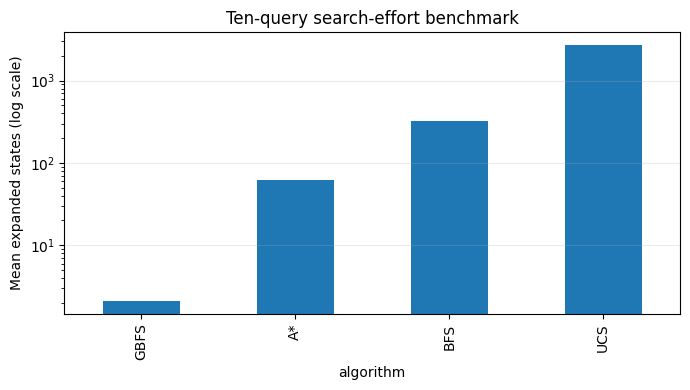

In [13]:
ax = summary.mean_expanded.sort_values().plot.bar(figsize=(7, 4), logy=True)
ax.set(ylabel="Mean expanded states (log scale)", title="Ten-query search-effort benchmark")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(RESULTS / "benchmark_expansions.png", dpi=160)
print("Saved:", sorted(p.name for p in RESULTS.iterdir()))
print("Terminal command (from all_experiments): python -m pytest utils -q")